# Sentence Embeddings for Document (News) Clustering

This notebook provides an example of text clustering using:
* [SentenceTransformers](https://www.sbert.net/) python library,
* a pre-trained sentence embeddings model, available from the [HuggingFace](https://huggingface.co/models) repository, and
* a hierarchical clustering algorithm.

In addition, the notebook exemplifies the use of the [t-SNE](https://lvdmaaten.github.io/tsne/) dimensionality reduction technique to plot and visually examine documents after transforming them into vectors.

Finally, it shows how we may use TF-IDF vectoriser to extract key ngrams in each cluster, so that we can better understand the documents in individual clusters.<br>

The data used in the example originate from Kaggle' [BBC News](https://www.kaggle.com/datasets/gpreda/bbc-news) dataset.

### Install and import the required libraries

If running the notebook in Colab, uncomment the next cell; if running it locally, first install packages `sentence-transformers` and `pypalettes`.

Note: `pypalettes` is a collection of 2500+ palettes curated by experts; https://github.com/y-sunflower/pypalettes

In [2]:
# !pip -q install sentence-transformers
# !pip -q install pypalettes

In [3]:
import pandas as pd
import numpy as np

# module for dimensionality reduction
from sklearn.manifold import TSNE

# modules for clustering
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as shc
from scipy.spatial.distance import pdist

# modules for plotting
import matplotlib.pyplot as plt
import seaborn as sb
from pypalettes import load_cmap

from pathlib import Path
from dotenv import load_dotenv
import os

# import warnings

RAND_STATE = 1

# A pretrained sentence embeddings model to use
PRETRAINED_LM = "all-MiniLM-L12-v2"

In [4]:
# warnings.filterwarnings('ignore', category=DeprecationWarning)

# for building a sentence embeddings model
from sentence_transformers import SentenceTransformer

For an overview of pretrained language models offered by HuggingFace, see: [https://www.sbert.net/docs/pretrained_models.html](https://www.sbert.net/docs/pretrained_models.html)

## Load the required resources

Start by loading the data from the 'bbc_news.csv' file:

In [5]:
# in case of running the notebook in Colab
#
# from google.colab import files
#
# data_file = files.upload()
# file_name = list(data_file.keys())[0]

In [6]:
# in case of running the notebook locally
file_name = Path.cwd() / 'data' / 'bbc_news.csv'

In [7]:
data = pd.read_csv(file_name)
data.head()

,title,pubDate,guid,link,description
0,Ukraine: Angry Zelensky vows to punish Russian...,"Mon, 07 Mar 2022 08:01:56 GMT",https://www.bbc.co.uk/news/world-europe-60638042,https://www.bbc.co.uk/news/world-europe-606380...,The Ukrainian president says the country will ...
1,War in Ukraine: Taking cover in a town under a...,"Sun, 06 Mar 2022 22:49:58 GMT",https://www.bbc.co.uk/news/world-europe-60641873,https://www.bbc.co.uk/news/world-europe-606418...,"Jeremy Bowen was on the frontline in Irpin, as..."
2,Ukraine war 'catastrophic for global food',"Mon, 07 Mar 2022 00:14:42 GMT",https://www.bbc.co.uk/news/business-60623941,https://www.bbc.co.uk/news/business-60623941?a...,One of the world's biggest fertiliser firms sa...
3,Manchester Arena bombing: Saffie Roussos's par...,"Mon, 07 Mar 2022 00:05:40 GMT",https://www.bbc.co.uk/news/uk-60579079,https://www.bbc.co.uk/news/uk-60579079?at_medi...,The parents of the Manchester Arena bombing's ...
4,Ukraine conflict: Oil price soars to highest l...,"Mon, 07 Mar 2022 08:15:53 GMT",https://www.bbc.co.uk/news/business-60642786,https://www.bbc.co.uk/news/business-60642786?a...,Consumers are feeling the impact of higher ene...


In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 42115 entries, 0 to 42114
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   title        42115 non-null  str  
 1   pubDate      42115 non-null  str  
 2   guid         42115 non-null  str  
 3   link         42115 non-null  str  
 4   description  42115 non-null  str  
dtypes: str(5)
memory usage: 14.2 MB


In [9]:
data.duplicated().sum()

np.int64(0)

Considering that the dataset is quite large and thus may slow down the data processing steps, we will use in the analysis only a subset of news originating from the same year.

So, we need to extract year from the <pubDate> column and use it for data filtering:

In [10]:
try:
  data['pub_date'] = pd.to_datetime(data.pubDate, format="%a, %d %b %Y %H:%M:%S GMT", errors='raise')
except ValueError as err:
  print(err)

In [11]:
data['pub_year'] = data.pub_date.dt.year
data.pub_year.value_counts()

pub_year
2023    15043
2024    14761
2022    12301
2021        6
2019        1
2017        1
2013        1
2018        1
Name: count, dtype: int64

Let's focus on a subset of the most recent news - those from 2024. Since this is still fairly large (for efficient processing), we will take a random sample of N=4000 entries

In [12]:
data2024 = data.loc[data.pub_year == 2024,].sample(n=4000, random_state=RAND_STATE).copy()

# drop columns that are no longer needed
data2024.drop(columns=['pub_year', 'pubDate'], inplace=True)

data2024.reset_index(drop=True, inplace=True)
data2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   title        4000 non-null   str           
 1   guid         4000 non-null   str           
 2   link         4000 non-null   str           
 3   description  4000 non-null   str           
 4   pub_date     4000 non-null   datetime64[us]
dtypes: datetime64[us](1), str(4)
memory usage: 1.2 MB


We will merge the `title` and `description` fields to obtain an overall textual content of each news, which we will then use in news processing and clustering.

In [13]:
data2024['content'] = data2024.apply(lambda row: f"{row['title']}. {row['description']}", axis=1)
data2024[['title','description','content']].head(10)

,title,description,content
0,Train strikes: What routes are affected when?,"Train drivers have been staging strikes, coinc...",Train strikes: What routes are affected when?....
1,'I'm not Harry Potter' - Ten Hag defends Man U...,Manchester United manager Erik ten Hag says he...,'I'm not Harry Potter' - Ten Hag defends Man U...
2,Thousands more appointments hit by doctor strike,"The NHS England said 91,000 appointments and p...",Thousands more appointments hit by doctor stri...
3,"Labour manifesto all about wealth creation, sa...","Sir Keir Starmer says there will be ""no surpri...","Labour manifesto all about wealth creation, sa..."
4,In defence of Foden - 'this is a tactical issu...,BBC pundit Micah Richards argues Phil Foden's ...,In defence of Foden - 'this is a tactical issu...
5,Train ticket machines charging double online p...,Which? has said the best value fares are eithe...,Train ticket machines charging double online p...
6,'I didn’t give up the win. I lost it off the l...,Lando Norris agonised over whether to hand vic...,'I didn’t give up the win. I lost it off the l...
7,Post Office scandal: Minister says he wants to...,"Kevin Hollinrake said that people ""must be hel...",Post Office scandal: Minister says he wants to...
8,'This is mine' - Coleman beats Lyles to 60m gold,Watch as American Christian Coleman beats comp...,'This is mine' - Coleman beats Lyles to 60m go...
9,'Hole in the ground' nuclear bunker to go unde...,"""Quirky"" buyer is sought for the nuclear bunke...",'Hole in the ground' nuclear bunker to go unde...


Check the lenght of the newly created textual column in terms of word count

In [14]:
data2024['word_count'] = data2024.content.apply(lambda c: len(c.split()))
data2024['word_count'].describe()

count    4000.000000
mean       26.443750
std         4.854454
min         5.000000
25%        23.000000
50%        26.000000
75%        29.000000
max        51.000000
Name: word_count, dtype: float64

This indicates that we have rather short texts, which are suitable for [SBERT's original pretrained models](https://www.sbert.net/docs/pretrained_models.html) considering that they can process up to 256 tokens (~ 170 - 200 words).

**Note**: BERT (and consequently, SBERT) uses a WordPiece tokenizer rather than splitting strictly by spaces. Common words correspond to 1 token, while long, rare, or compound words get split into multiple subword pieces (e.g., `outstandingly` gets split into `outstanding` and `##ly`). Expansion factor for English words is 1.1 to 1.5 tokens per word.

#### Getting access to HuggingFace models

Next, we instantiate a sentence embedding model using a pre-trained embeddings model from HuggingFace.

Note: To be able to use models from the HuggingFace repo, one needs a HuggingFace access token. To obtain one, you would, first, need to set up an account at [HuggingFace.co](https://huggingface.co/). After logging in, click on the profile in the top-right corner, then follow these steps: click *Settings* > click *Access Tokens* > click *New Token* > set *Role* to *write* > *Generate*.

If running this notebook in Google colab, the generated token can be stored in **Colab Secrets**, which is a recommended way of securely storing access tokens and API keys. To learn how to do that and how then to access API tokens / keys stored as Secrets, see, for example, [this short article](https://labs.thinktecture.com/secrets-in-google-colab-the-new-way-to-protect-api-keys/).

If running the notebook localy, you may want to store the token in the `.env` file (HF_TOKEN=token_value) and load it as shown below:

In [15]:
load_dotenv()

if os.getenv('HF_TOKEN'):
    print('successfully loaded HF token')
else:
    print('Failed to load HF token')

successfully loaded HF token


In [16]:
# warnings.filterwarnings('ignore')

model = SentenceTransformer(PRETRAINED_LM)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

According to it's [model card](https://huggingface.co/sentence-transformers/all-MiniLM-L12-v2), the pretrained model that we've loaded
maps sentences & paragraphs to a 384 dimensional dense vector space and can be used for tasks like clustering or semantic search. It is trained on a large and diverse dataset of over 1 billion training pairs.

The embeddings are normalized, meaning that the vector length (or magnitude) is 1. This is suitable for the subsequent task of computing vector similarity (i.e., similarity of news they represent) as only the direction of the vector is considered, not its magnitude.

## Clustering of news items

To be able to cluster documents (news), we need a way of estimating how similar or close they are to one another. To that end, we will:
1) Transform each document (news item) into its vector representation (embedding)
2) Use cosine similarity to compute the similarity of news vectors

### Step 1. Create news embeddings

In [30]:
# warnings.filterwarnings('ignore')

news_embeddings = model.encode(data2024['content'].to_numpy(), # need to transform pd.Series to np.narray as that's what the encode method requires
                               normalize_embeddings=True) # to be sure that embeddings are normalized (relevant for later use in distance computation)

In [31]:
news_embeddings.shape

(4000, 384)

In [32]:
news_embeddings[:5,]

array([[ 0.04113673, -0.02983468, -0.0055119 , ...,  0.00748834,
         0.00931514,  0.03954288],
       [-0.08120068,  0.06985081,  0.00346192, ..., -0.00491071,
        -0.04686562, -0.02456839],
       [-0.03069467, -0.00363699, -0.01168084, ..., -0.00084322,
         0.01408119,  0.05806176],
       [-0.02642015,  0.07772516,  0.04414247, ..., -0.01286601,
         0.11840677,  0.00778098],
       [ 0.01402361,  0.07168365, -0.06727008, ..., -0.00772562,
         0.04792241,  0.0822399 ]], shape=(5, 384), dtype=float32)

#### Step 2. Compute similarity of news based on their embeddings

Similarity of documents expressed as vectors is typically estimated using [cosine similarity measure](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html)

In [33]:
news_similarities = cosine_similarity(news_embeddings, news_embeddings)
news_similarities.shape

(4000, 4000)

Take one news item and explore those that are most similar to it

In [34]:
sample_news_item = data2024.content.sample(random_state=RAND_STATE)

sample_index = sample_news_item.index[0]
sample = sample_news_item.iloc[0]

print(sample)
print(sample_index)

Burrow was sporting great and inspiring MND campaigner. A champion on and off the field, Rob Burrow's determination, courage and humility ensures a legacy that stretches way beyond rugby league.
200


In [35]:
n_news = news_similarities.shape[0]
pairs_scores = [{'pair':i, 'score':news_similarities[sample_index,i]} for i in range(n_news) if i != sample_index]

sorted_pair_scores = sorted(pairs_scores, key=lambda pair: pair['score'], reverse=True)

print("Five most similar news:")
for pair in sorted_pair_scores[:5]:
    paired_news = data2024.content[pair['pair']]
    print(f"NEWS: {paired_news}\nSimilarity score: {pair['score']:.4f}\n")

Five most similar news:
NEWS: Rugby League legend Rob Burrow dies aged 41. The Leeds Rhinos star was diagnosed with motor neurone disease two years after he retired from playing, following a stellar 17-year career.
Similarity score: 0.7049

NEWS: A giant and an 'absolute legend' - remembering Rob Burrow. BBC Sport looks back at Rob Burrow's greatest achievements, featuring tributes from his family and friends, after the rugby league legend and motor neurone disease campaigner died aged 41.
Similarity score: 0.6770

NEWS: 'Hero Rob's final message' and Farage returns. Nigel Farage's return and Rob Burrow's inspiring final voice note lead Tuesday's papers.
Similarity score: 0.3833

NEWS: Garth Crooks' Team of the Week: Saka, Haaland, Rice, Gallagher. Which players impressed our football pundit Garth Crooks enough to make his latest Team of the Week?
Similarity score: 0.3625

NEWS: Home damage victim shocked by rugby captain choice. A year before naming Cory Hill captain, Wales coach met 

#### Step 3: Hierarchical agglomerative clustering of (embedded) news items

We will now use agglomerative hierarchical clustering to group (cluster) news based on their (cosine) similarity,

Agglomerative clustering works in a “bottom-up” manner:
* each instance is initially considered as a single-element cluster (leaf);
* then, at each step of the algorithm, two clusters that are the most similar are combined into a new bigger cluster (node). This procedure is repeated until all items are members of just one single big cluster (root).

The similarity of any two clusters is computed based on similarity of the instances that form the clusters and this computation can be done in different ways, that is, using different methods, which are called *linkage* methods. Here, we will use the most often used linkage method - the Ward's algorithm, which aims at minimizing the total within-cluster variance.

[This blog post](https://dataaspirant.com/hierarchical-clustering-algorithm/) provides a nice visual introduction to agglomerative hierarchical clustering.

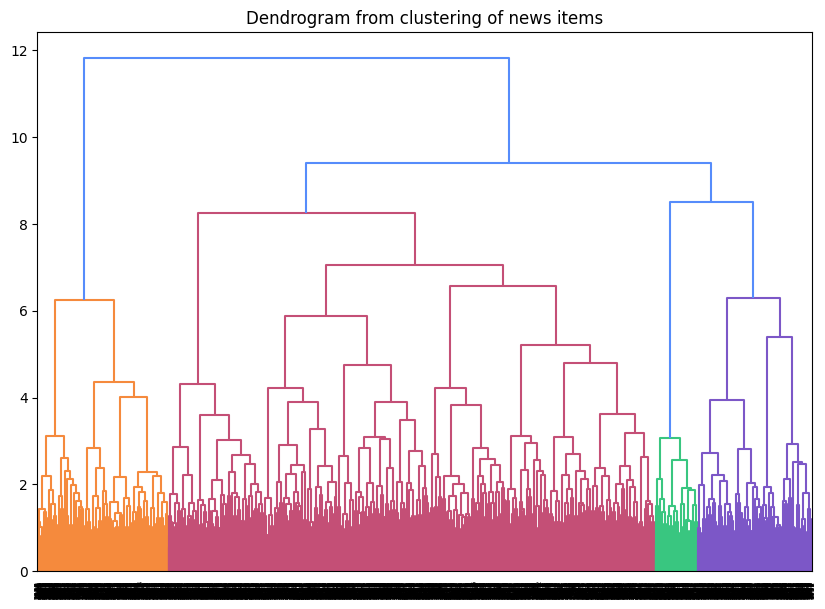

In [37]:
# note: pdist computes and returns distances of the given items (news_embeddings in this case) in the format required by the linkage function
ward_linkage = shc.linkage(pdist(news_embeddings, metric='cosine'), method='ward')

plt.figure(figsize=(10, 7))
shc.dendrogram(ward_linkage)
plt.title('Dendrogram from clustering of news items')
plt.show()

Denodrogram suggests any number between 3 or 6 clusters as a potential solution, so we need additional indicators to make the decision

##### Use silhouette to compare alternative clustering options

There is a variety of measures used for estimating the quality of a clustering solution and comparing alternative solutions. A frequently used one is *silhouette score*, which indicates how similar an object is to its own cluster compared to other clusters. More precisely, it is based on two measures:
* Cohesion $a(i)$ — "Intra-cluster cohesion": The average distance from data point $i$ to all other points within the same cluster.
* Separation $b(i)$ — "Nearest neighbor distance":  The average distance from data point $i$ to all points in the nearest neighboring cluster (the closest cluster that point i does not belong to)

Silhouette for one item is computed as follows: $$s(i) = \frac{b(i) - a(i)}{\max\big(a(i), b(i)\big)}$$

Then, it is averaged across all the items in the dataset: $$S = \frac{1}{N} \sum_{i=1}^{N} s(i)$$

The silhouette score ranges from −1 to +1, with a high value indicating that an instance is well matched to its own cluster and poorly matched to neighboring clusters; negative values suggest the opposite.

To determine the optimal number of clusters, we will identify cluster assignments for different number of clusters (3 - 6) and for each one compute average silhouette score across all observations; the one with the highest score will be chosen.

For the computation of silhouette score we need distances among news items in the same cluster as well as distances from items in other clusters. Since we have already computed similarities of news items (and stored them in `news_similarities`), with a minor additional transformation, these similarities can be turned into distances:<br>
`cosine_distance = 1 - cosine_similarity`

In [38]:
silhouette_scores = []

news_distances = 1 - news_similarities
# Ensure no distance value is less than 0.0;
# added to fix an issue with very tiny negative values that prevented further use of the distance matrix
news_dist_clipped = np.clip(news_distances, a_min=0.0, a_max=None)

for k in range(3, 7):
  # fcluster identifies a specific clustering from the linkage matrix and the given number of clusters
  agg_clust = shc.fcluster(ward_linkage, t=k, criterion='maxclust')
  sil_score = silhouette_score(news_dist_clipped, agg_clust, metric='precomputed')
  silhouette_scores.append(sil_score)

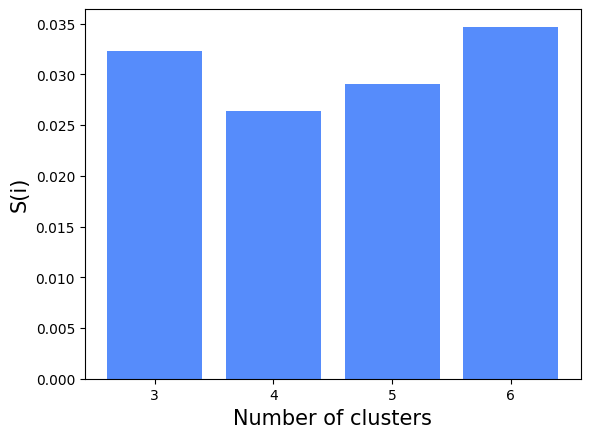

In [39]:
# Plotting a bar graph to compare the results
plt.bar(range(3, 7), silhouette_scores)
plt.xlabel('Number of clusters', fontsize = 15)
plt.ylabel('S(i)', fontsize = 15)
plt.xticks(range(3,7))
plt.show()

Silhouette scores suggest 6 clusters as the best solution. This is also fine based on what the dendrogram shows. So, let's examine the 6 cluster solution.

Note also the very low average silhouette score values - this suggests that the clusters are not well separated (as can be expected for news stories).

First, we check how large and balanced the clusters are:

In [47]:
agg_clust_opt = shc.fcluster(ward_linkage, t=6, criterion='maxclust')
pd.Series(agg_clust_opt).value_counts().sort_index()

1     677
2     493
3     854
4    1166
5     219
6     591
Name: count, dtype: int64

This is not perfect in terms of the balance in cluster size, but based on the dendrogram, a lackin balance would be present regardless of the (meaningful) number of clusters we choose.

#### Step 4: Characterise clusters by their keywords

To get an idea what each cluster is about, we will extract the most relevant ngrams (based on TF-IDF score) from each cluster and use them to characterize the clusters.

In [41]:
data2024['cluster'] = agg_clust_opt

def get_top_ngrams(cluster_id, top_n=10, words_to_remove=None):

    tfidf_vectorizer = TfidfVectorizer(
        stop_words='english',
        ngram_range=(1, 2)
    )

    cluster_news = data2024.loc[data2024.cluster == cluster_id].content
    cluster_tfidf = tfidf_vectorizer.fit_transform(cluster_news)
    candidate_keywords = tfidf_vectorizer.get_feature_names_out()

    # za svaki ngram racuna prosecni TF-IDF kroz sve vesti u klasteru i
    # transformise u jednodimenzionalni vektor
    mean_tfidf = np.asarray(cluster_tfidf.mean(axis=0)).flatten()

    # kreiramo uredjeni par (ngram, tf-idf score) i sortiramo u opadajucem redosledu tf-idf score-a
    sorted_candidates = sorted([(keyword, tfidf_score) for keyword, tfidf_score in zip(candidate_keywords, mean_tfidf)], key=lambda item: item[1], reverse=True)

    if words_to_remove:
        sorted_candidates = [(keyword, score) for keyword, score in sorted_candidates if keyword not in words_to_remove]

    return sorted_candidates[:top_n]

Present the keywords and their scores visually

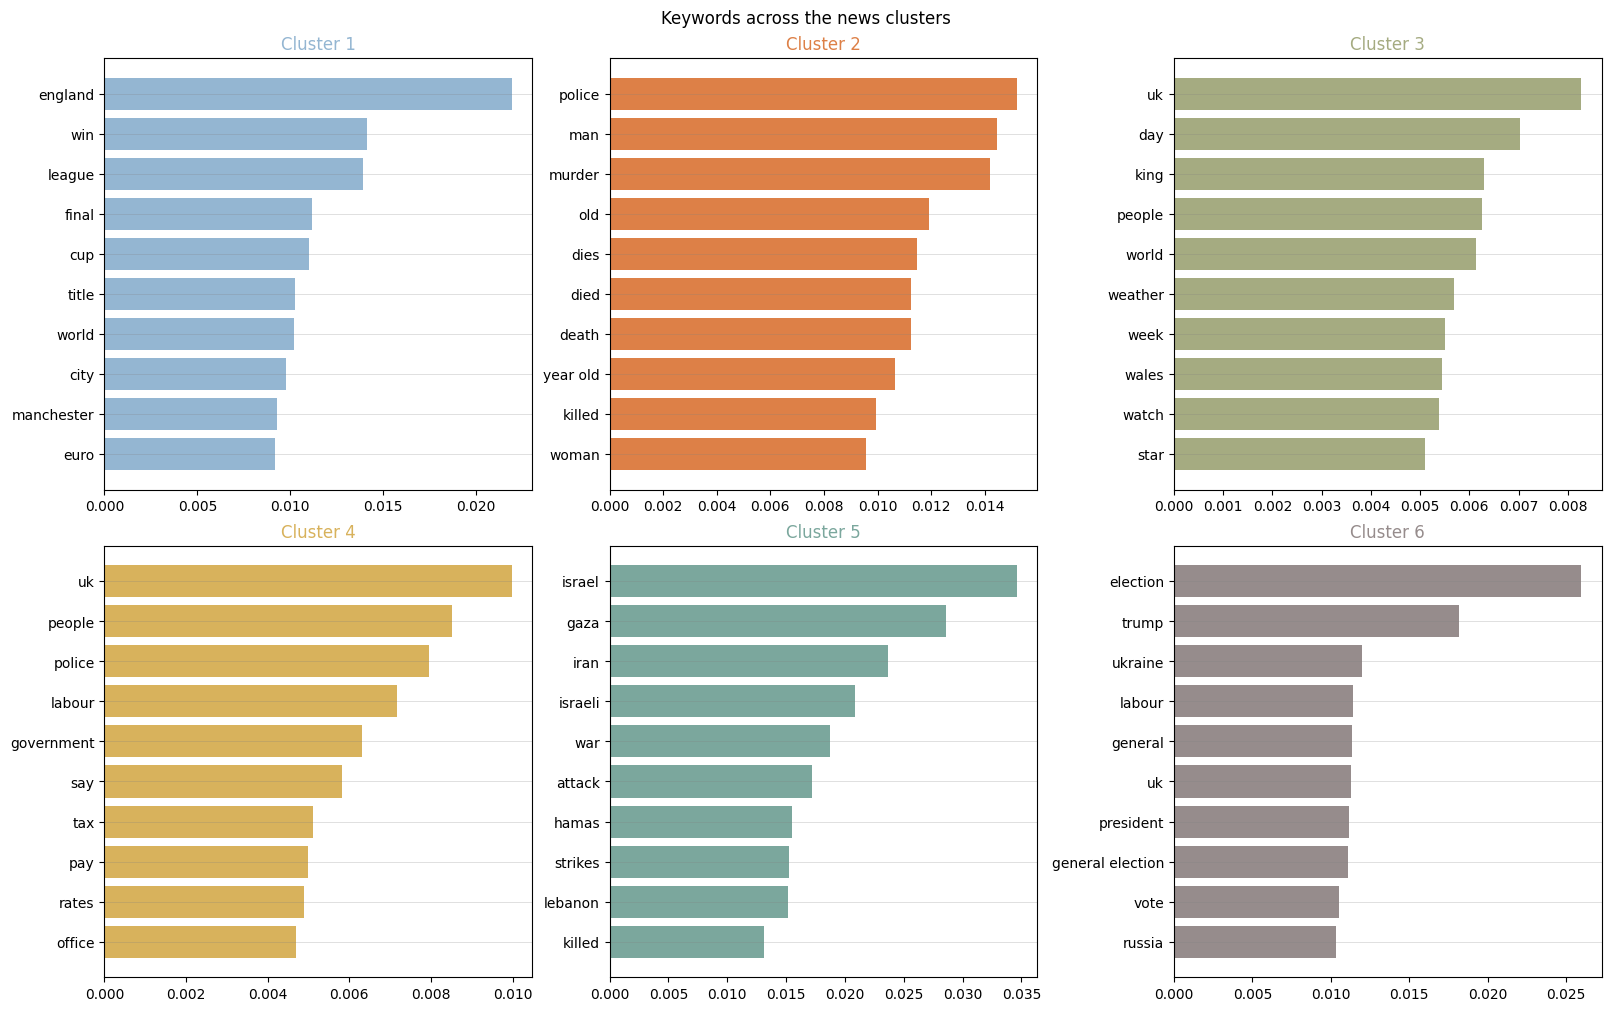

In [49]:
fig, ax_grid = plt.subplots(nrows=2, ncols=3, figsize=(16, 10), constrained_layout=True)
axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = data2024['cluster'].nunique()
for i in range(n_clust):

    data = get_top_ngrams(i+1, words_to_remove=['bbc','says', '2024', 'new', 'year','years'])
    data = sorted(data, key=lambda item: item[1])
    scores = [s for kw, s in data]
    keywords = [kw for kw, s in data]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i+1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)

fig.suptitle("Keywords across the news clusters")

plt.show()


#### Optional: Use t-SNE to reduce the dimensionality of news representation and visualise cluster assignments

We will use a dimensionality reduction method to reduce the dimensionality of the news representation, so that we can visually explore distinct clustering solutions.

t-SNE is a dimensionality reduction technique that is often used for exploration of high-dimensional data. The main advantage of t-SNE is its ability to preserve local structure in the data, meaning that points that are close to one another in a high-dimensional dataset will still be close to one another in the (dimensionaly) reduced dataset and if the new dataset is 2-dimensional and plotted, they will be close to one another in the plot.

We will use t-SNE here to reduce the *news_embeddings* data from 384 dimensions to 2 dimensions and plot news items across distinct cluster assignments

In [43]:
tsne = TSNE(n_components=2,
            perplexity=30, # key argument for fine-tuning, see below
            max_iter=1500,
            metric='cosine',
            verbose=1,
            random_state=RAND_STATE)

z = tsne.fit_transform(news_embeddings)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 4000 samples in 0.001s...
[t-SNE] Computed neighbors for 4000 samples in 0.264s...
[t-SNE] Computed conditional probabilities for sample 1000 / 4000
[t-SNE] Computed conditional probabilities for sample 2000 / 4000
[t-SNE] Computed conditional probabilities for sample 3000 / 4000
[t-SNE] Computed conditional probabilities for sample 4000 / 4000
[t-SNE] Mean sigma: 0.237601
[t-SNE] KL divergence after 250 iterations with early exaggeration: 85.732971
[t-SNE] KL divergence after 1500 iterations: 1.906368


Note: *perplexity* is one of the key paramters for fine-tuning dimensionality reduction done by t-SNE since it determines if we care more about the local structure of the data or a 'big-picture': a low perplexity means we care about local scale and focus on the closest points; high perplexity takes more of a "big picture" approach. Recommended values are in the 5-50 range, and default is 30. We will use here the default value and you may want to experiment with higher / lower values to explore how the visualisations and patterns in the data change.

In [44]:
z.shape

(4000, 2)

Now that we have the news content as 2-dimensional vectors, we can add cluster assignments and plot them

In [45]:
reduced_embeddings_df = pd.DataFrame()
reduced_embeddings_df["comp-1"] = z[:,0]
reduced_embeddings_df["comp-2"] = z[:,1]
reduced_embeddings_df['clust'] = agg_clust_opt

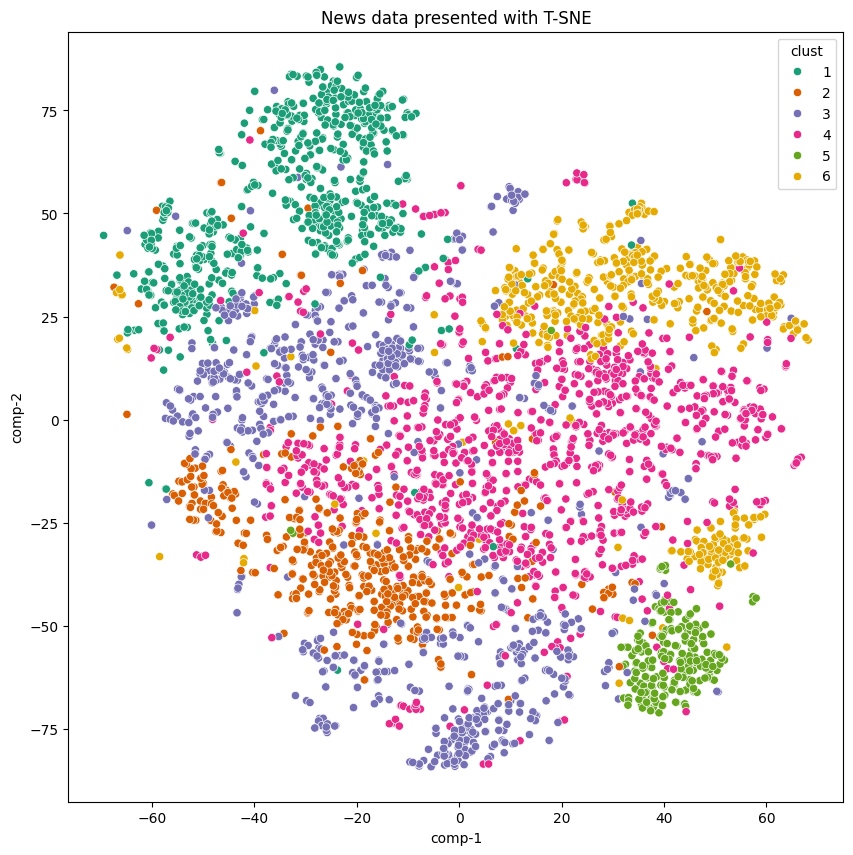

In [46]:
plt.figure(figsize=(10,10))
sb.scatterplot(x='comp-1', y='comp-2', data=reduced_embeddings_df, hue='clust', palette='Dark2')
plt.title("News data presented with T-SNE")
plt.show()

If interested in learning how to fine tune t-SNE to get an optimal 2D representation of data, [this blog post](https://danielmuellerkomorowska.com/2021/01/05/introduction-to-t-sne-in-python-with-scikit-learn/) might be a good point to start from.

The plot above suggests that clusters are not well separated, which is in line with the very low average silhouette value.

We will try to better understand the clusters by associating them with keywords.